In [1]:
import tempfile

import numpy as np
import healpy as hp
from matplotlib import pyplot as plt

import litebird_sim as lbs
import ducc0
from time import time

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import LinearOperator, cg

In [2]:
nside = 128

In [3]:
lmax = 2 * nside
kmax = 2            #beam mmax
npix = hp.nside2npix(nside)

resol_arcmin = hp.nside2resol(nside, arcmin=True)
fwhm_arcmin = 3.5 * resol_arcmin

#LiteBIRD scans the sky at approximately 90 arcmin / sec
omega_scan = 90
fwhm_crossing_time = fwhm_arcmin / omega_scan
sampling_rate_hz = 1 / fwhm_crossing_time * 3.5

In [4]:
###############################################################################
####### Producing the input maps, pointings and TODs using litebird_sim #######
###############################################################################


### Mission parameters (one year of observation)
start_time = 51
mission_time_days = 365.25


### Simulation parameters
random_seed = 0
imo_version = "vPTEP"
imo = lbs.Imo(flatfile_location=lbs.PTEP_IMO_LOCATION)
dtype_float = np.float64
tmp_dir = tempfile.TemporaryDirectory()


### Scanning strategy parameters (LiteBIRD-like)
spin_sun_angle_deg = 37.5
spin_sun_angle_rad = np.deg2rad(spin_sun_angle_deg)
spin_boresight_angle_rad = np.deg2rad(95-spin_sun_angle_deg)
spin_rate_hz = 0.3 / 60.0
precession_rate_hz = 1/(192.348 * 60)


### Initializing the simulation
sim = lbs.Simulation(
        random_seed=random_seed,
        base_path=tmp_dir.name,
        name="test",
        start_time=start_time,
        duration_s=mission_time_days * 24 * 60 * 60.0,
        imo=imo,
        )


### Instrument info
instr_info = lbs.InstrumentInfo(
    spin_boresight_angle_rad = spin_boresight_angle_rad,
)

sim.set_instrument(instr_info)


### Scanning strategy
sim.set_scanning_strategy(
    scanning_strategy=lbs.SpinningScanningStrategy(
        spin_sun_angle_rad=spin_sun_angle_rad,
        spin_rate_hz=spin_rate_hz,
        precession_rate_hz=precession_rate_hz,
    )
)

### Channel info
ch_info = lbs.FreqChannelInfo(
    bandcenter_ghz=100.0,                   # value for "MF1-100" from Option 1 IMo
    bandwidth_ghz=0.23,                     # value for "MF1-100" from Option 1 IMo
    fwhm_arcmin=fwhm_arcmin,
    sampling_rate_hz=sampling_rate_hz,
)


### Detector list
pol_angles_rad = [0.]
n_detectors = len(pol_angles_rad)

detector_list = []
for i in range(n_detectors):
    det = ch_info.get_boresight_detector(name=f"Dummy_det_#{i+1}")
    det.pol_angle_rad = pol_angles_rad[i]
    detector_list.append(det)


### Create observations
sim.create_observations(
        detectors=detector_list,
        num_of_obs_per_detector=1,
        n_blocks_det=1,
        n_blocks_time=1,
        split_list_over_processes=False,
        tod_dtype=dtype_float,
)


### Input d0s0
sky_params = lbs.SkyGenerationParams(
    make_cmb=False,
    make_fg=True,
    fg_models=["d0", "s0"],  # set the FG models you want
    apply_beam=False,  # if True, smooths the input map by the beam of the channel
    bandpass_integration=False,  # if True, integrates over the top-hat bandpass of the channel
    units="K_CMB",
    output_type="alm",
    nside=nside,
    lmax=lmax,
)

sky = sim.get_sky(parameters=sky_params, channels=ch_info, store_in_observation=True)


### Remove polarization
alms = sim.get_sky(parameters = sky_params)
alms['Dummy_det_#1'].values[1:] *= 0


### Smooth sky alms (for comparison)
#alm = np.copy(alms['Dummy_det_#1'].values[0])
alms_smoothed = np.copy(alms['Dummy_det_#1'].values[0])
alms_smoothed = hp.smoothalm(alms_smoothed, fwhm=np.deg2rad(fwhm_arcmin/60))


### Define Gaussian beams
blms = sim.get_gauss_beam_alms(lmax=lmax, mmax=kmax)


### Prepare pointings
sim.prepare_pointings()
sim.precompute_pointings()


### Define convolution parameters
Convparams = lbs.BeamConvolutionParameters(
    lmax = lmax,
    mmax = kmax,
    single_precision = False,
    epsilon = 1e-5,
)

# Scan the map and fill tod
lbs.add_convolved_sky_to_observations(
    sim.observations,
    alms,
    blms,
    convolution_params=Convparams,
)

tod = sim.observations[0].tod[0]



[2026-10-20 11:03:15,722 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 11:03:15,722 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 11:03:17,394 WARNING MPI#0000] seed_cmb is None. This could lead to unexpected behavior in MPI jobs.
[2026-10-20 11:03:17,394 INFO MPI#0000] Generating Foregrounds...
[2026-10-20 11:03:17,395 INFO MPI#0000] Retrieve data for pysm_2/dust_t_new.fits (if not cached already)
[2026-10-20 11:03:17,396 INFO MPI#0000] NSIDE = 512
[2026-10-20 11:03:17,397 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 11:03:17,397 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 11:03:17,452 INFO MPI#0000] Retrieve data for pysm_2/dust_q_new.fits (if not cached already)
[2026-10-20 11:03:17,453 INFO MPI#0000] NSIDE = 512
[2026-10-20 11:03:17,453 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 11:03:17,453 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 1

In [5]:
### Binning
pointing_matrix = sim.observations[0].pointing_matrix

thetas = pointing_matrix[0,:,0]
phis = pointing_matrix[0,:,1]
pixs = hp.ang2pix(nside, thetas, phis)

row = np.arange(len(pixs))
col = pixs
data = np.ones(len(pixs))
response_matrix = csr_matrix((data, (row, col)), shape=(len(pixs), npix))

A = response_matrix.transpose().dot(response_matrix)
b = response_matrix.transpose().dot(tod)

# solve Ax = b
binned_map = cg(A, b)

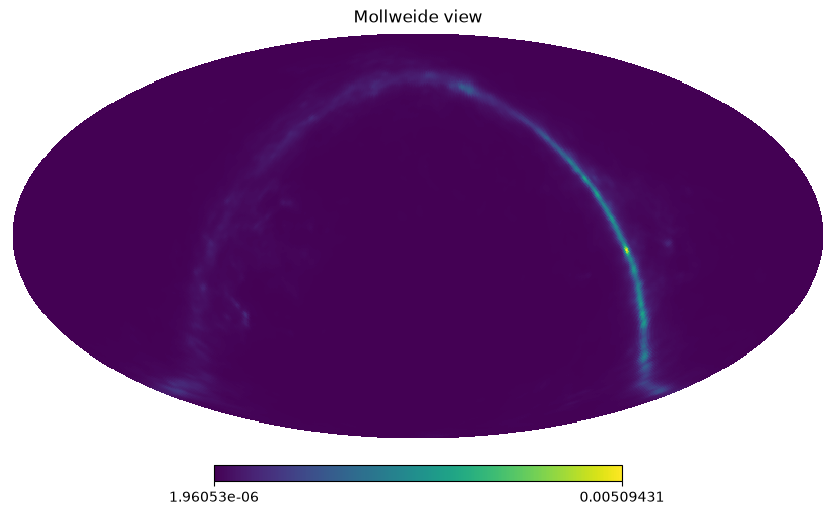

In [6]:
hp.mollview(binned_map[0])

In [7]:
### alm-making
# code adapted from https://github.com/mreineck/ducc/blob/ducc0/python/demos/sht_general.py
# and https://github.com/healpy/healpy/blob/446185ae8b3ef97b863d2726b1dd711a3f4d153f/lib/healpy/sphtfunc.py

spin = 0
epsilon = 1e-7
nthreads = 8
maxiter = 20
ncomp = 1
tol = 1e-7

npoints = len(pixs)
loc = np.empty((npoints,2), dtype=np.float64)
loc[:,0] = thetas
loc[:,1] = np.where(phis > 0, phis, phis+2*np.pi)

# helper functions to convert between real- and complex-valued a_lm
def alm2realalm(alm):
    alm = alm.reshape((ncomp, -1))
    res = np.zeros((ncomp, alm.shape[1] * 2 - lmax - 1))
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1].real
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.float64) * np.sqrt(2.0)
    return res.reshape((-1,))

def realalm2alm(alm):
    alm = np.array(alm).reshape((ncomp, -1))
    res = np.zeros((ncomp, (alm.shape[1] + lmax + 1) // 2), dtype=np.complex128)
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1]
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.complex128) * (
            np.sqrt(2.0) / 2
        )
    if ncomp == 1:
        res = res[0]
    return res

def a2t2(x):
    talm = realalm2alm(x)
    res = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    return res.reshape((-1,))

def t2a2(x):
    talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    res = alm2realalm(talm)
    return res

def ATA_func(x):
    return t2a2(a2t2(x))

def ATA_trans_func(x):
    return a2t2(t2a2(x))

b = t2a2(tod)

# We are explicitly setting "dtype" for the LinearOperator here because
# some (inadvertent?) changes in scipy 1.15 made this necessary
# (see, e.g., https://github.com/scipy/scipy/issues/22310).
op = LinearOperator(
    matvec=ATA_func, shape=(b.size, b.size),
    dtype=b.real.dtype
)

res = cg(
    A=op,
    b=b,
    x0=b,
    atol=tol,
    rtol=tol,
)

alm_ducc = realalm2alm(res[0])

[2026-10-20 11:04:11,772 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:04:11,772 INFO MPI#0000] -> fwhm is 0.000000 arcmin


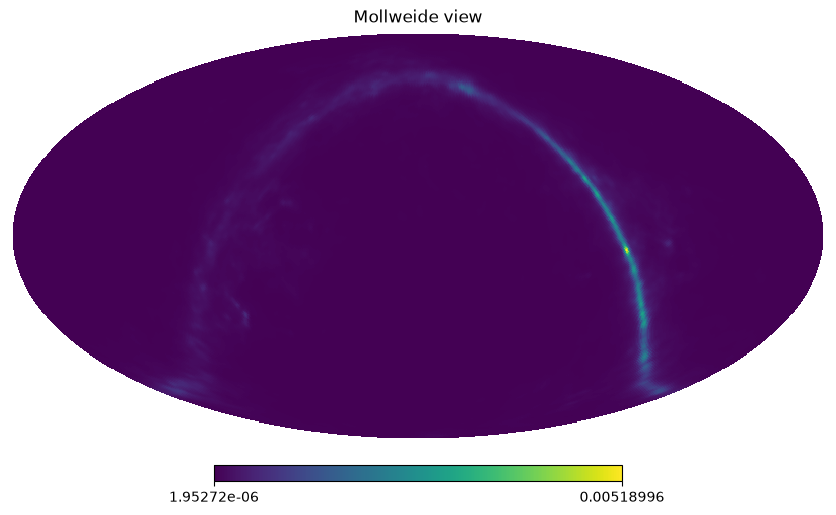

In [8]:
hp.mollview(hp.alm2map(alm_ducc, nside=nside))

In [9]:
Cls_in = hp.alm2cl(alms_smoothed, lmax=lmax)
Cls_map = hp.anafast(binned_map[0], lmax=lmax)
Cls_alm = hp.alm2cl(alm_ducc, lmax=lmax)

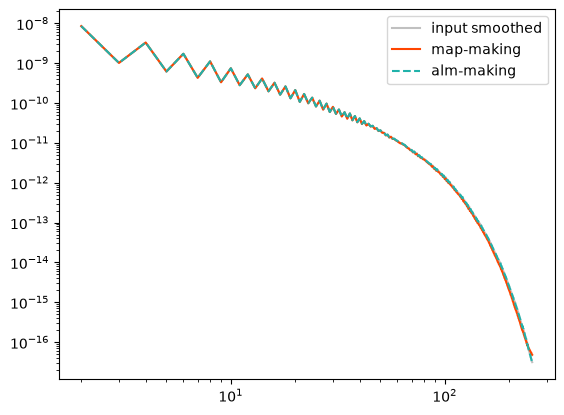

In [10]:
ell = np.arange(lmax+1)

plt.loglog(ell[2:], Cls_in[2:], color="silver", label="input smoothed")
plt.loglog(ell[2:], Cls_map[2:], color="orangered", label="map-making")
plt.loglog(ell[2:], Cls_alm[2:], color="lightseagreen", linestyle="dashed", label="alm-making")
plt.legend()
plt.show()

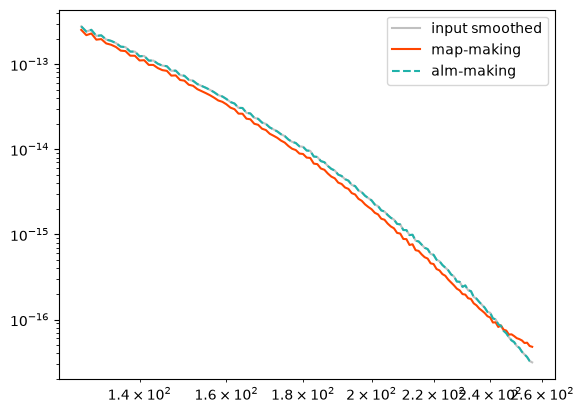

In [11]:
plt.loglog(ell[nside:], Cls_in[nside:], color="silver", label="input smoothed")
plt.loglog(ell[nside:], Cls_map[nside:], color="orangered", label="map-making")
plt.loglog(ell[nside:], Cls_alm[nside:], color="lightseagreen", linestyle="dashed", label="alm-making")
plt.legend()
plt.show()

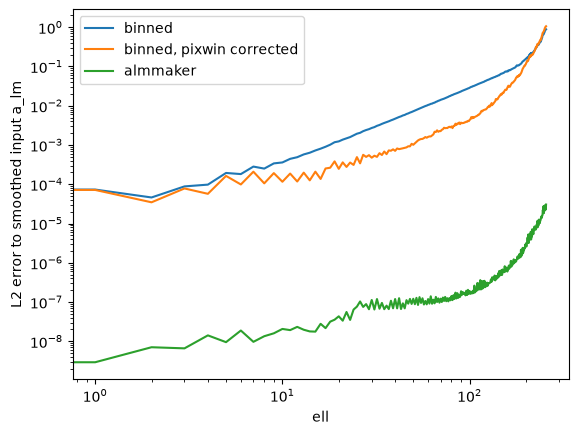

In [12]:
# Translation from lm index to l value
l_index = hp.Alm.getlm(lmax, np.arange(hp.Alm.getsize(lmax)))[0]

# first we have to rotate the ground truth a_lm from galactic to ecliptic
rot = hp.Rotator(coord=['G','E'])
alm_truth = rot.rotate_alm(alms_smoothed, lmax=lmax)

# get the a_lm from the binned map
alm_bin = hp.map2alm(binned_map[0], lmax=lmax)

# correct by pixel window
pixwin = hp.pixwin(nside,lmax)[0]
alm_bin_corr = alm_bin/pixwin[l_index]

# denominator for all of the L2 error calculations below
denom = np.zeros(lmax+1)
np.add.at(denom, l_index, np.abs(alm_truth)**2)

# plot error measure of binner result
num = np.zeros(lmax+1)
np.add.at(num, l_index, np.abs(alm_bin-alm_truth)**2)
plt.loglog(np.sqrt(num/denom), label="binned")

num = np.zeros(lmax+1)
np.add.at(num, l_index, np.abs(alm_bin_corr-alm_truth)**2)
plt.loglog(np.sqrt(num/denom), label="binned, pixwin corrected")

# plot error measure of ducc result
num = np.zeros(lmax+1)
np.add.at(num, l_index, np.abs((alm_truth-alm_ducc))**2)
plt.loglog(np.sqrt(num/denom), label="almmaker")

plt.xlabel("ell")
plt.ylabel("L2 error to smoothed input a_lm")
plt.legend()

plt.show()


[2026-10-20 11:04:12,312 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:04:12,312 INFO MPI#0000] -> fwhm is 0.000000 arcmin
[2026-10-20 11:04:12,350 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:04:12,350 INFO MPI#0000] -> fwhm is 0.000000 arcmin


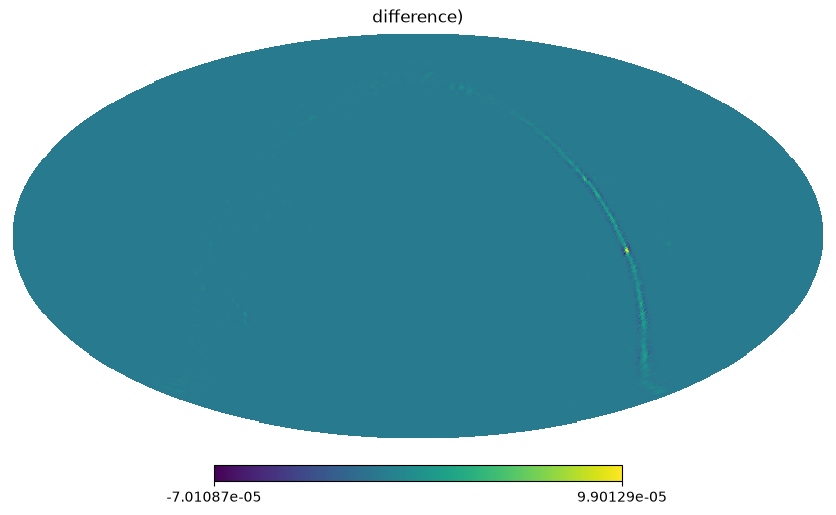

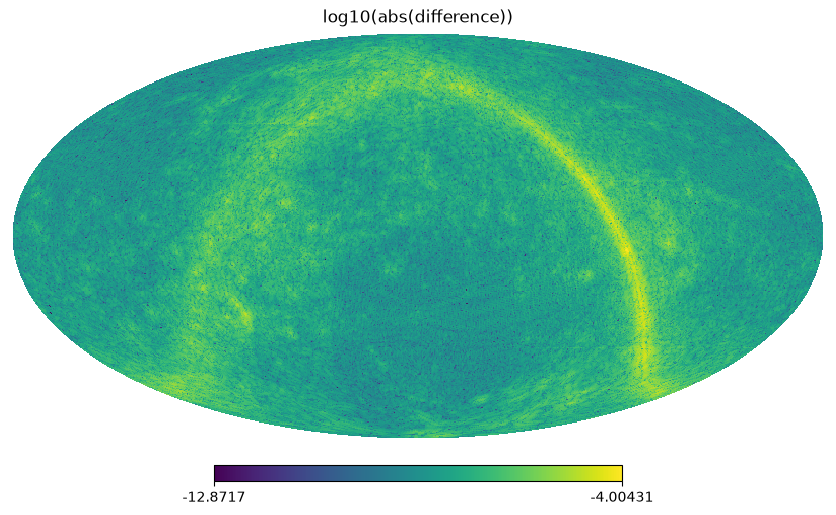

In [13]:
hp.mollview(hp.alm2map(alm_ducc, nside=nside)-binned_map[0],title="difference)")
hp.mollview(np.log10(np.abs(hp.alm2map(alm_ducc, nside=nside)-binned_map[0])),title="log10(abs(difference))")